In [1]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

Data Loading

In [2]:
# Load the dataset
df = pd.read_csv("Iris.csv")

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


Data Understanding

In [3]:
# Check the dimension
df.shape

(150, 6)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    object 
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [5]:
df.describe()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


Data Cleaning

In [6]:
# Check data quality
# Missing Value
df.isnull().sum()

,0
Id,0
SepalLengthCm,0
SepalWidthCm,0
PetalLengthCm,0
PetalWidthCm,0
Species,0


In [7]:
# Duplicate value
df.duplicated().sum()

np.int64(0)

In [8]:
# Remove Column Id
df = df.drop(columns="Id")

In [9]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [10]:
# Separate features and target
x = df.drop(columns="Species")
y = df["Species"]

In [11]:
y.value_counts()

,count
Species,
Iris-setosa,50
Iris-versicolor,50
Iris-virginica,50


Exploratory Data Analysis

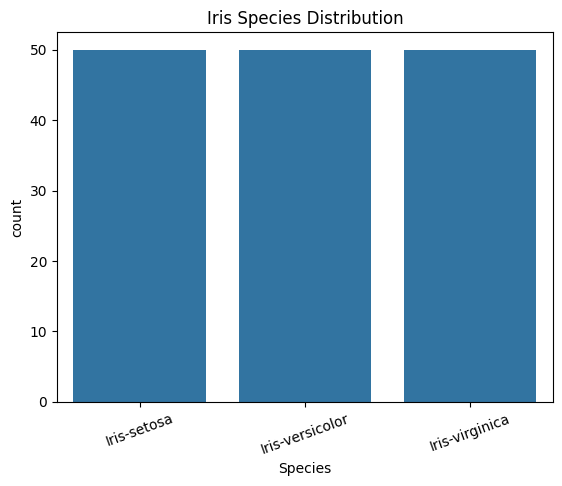

In [12]:
sns.countplot(data=df, x="Species")

plt.title("Iris Species Distribution")
plt.xticks(rotation=20)
plt.show()

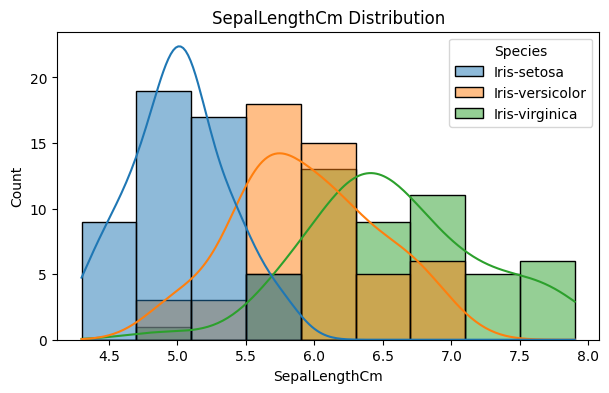

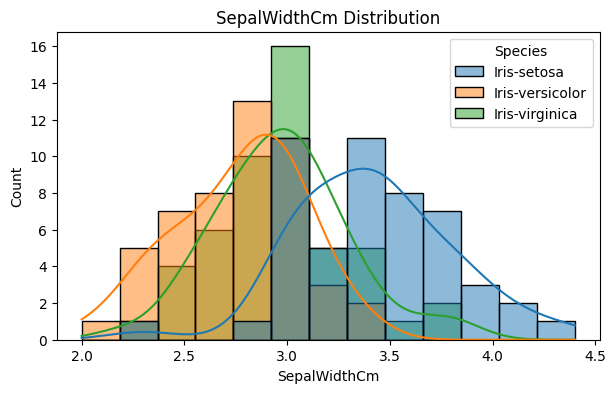

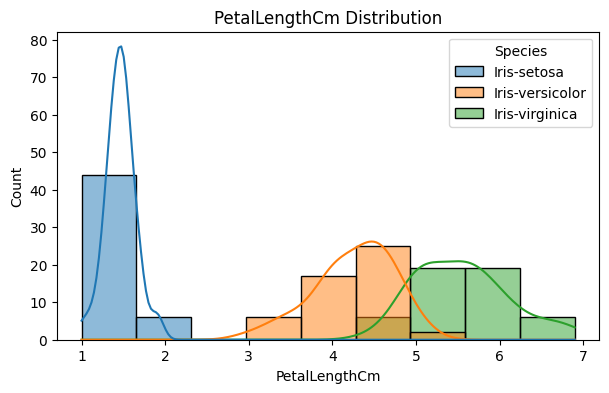

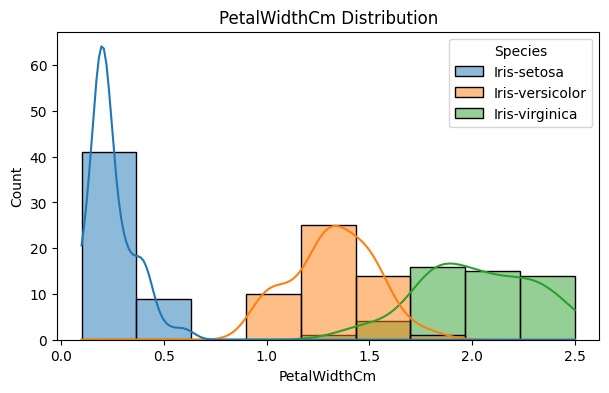

In [13]:
# Feature distribution
features = [
    "SepalLengthCm",
    "SepalWidthCm",
    "PetalLengthCm",
    "PetalWidthCm"
]

for feature in features:
    plt.figure(figsize=(7,4))
    sns.histplot(data=df, x=feature, hue="Species",kde=True)
    plt.title(f"{feature} Distribution")
    plt.show()

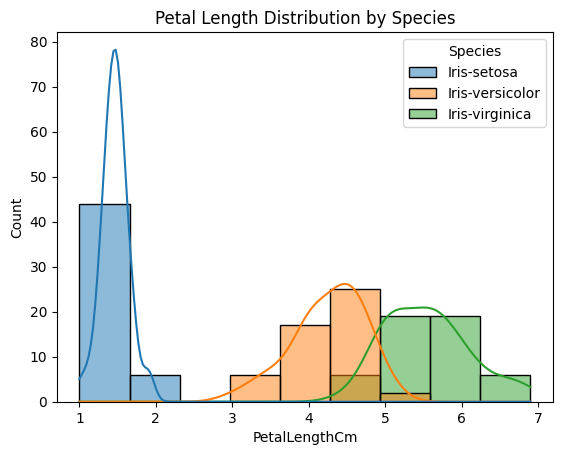

In [14]:
# Compare Petal Length by Species
sns.histplot(
    data=df,
    x='PetalLengthCm',
    hue='Species',
    kde=True
)

plt.title("Petal Length Distribution by Species")
plt.show()

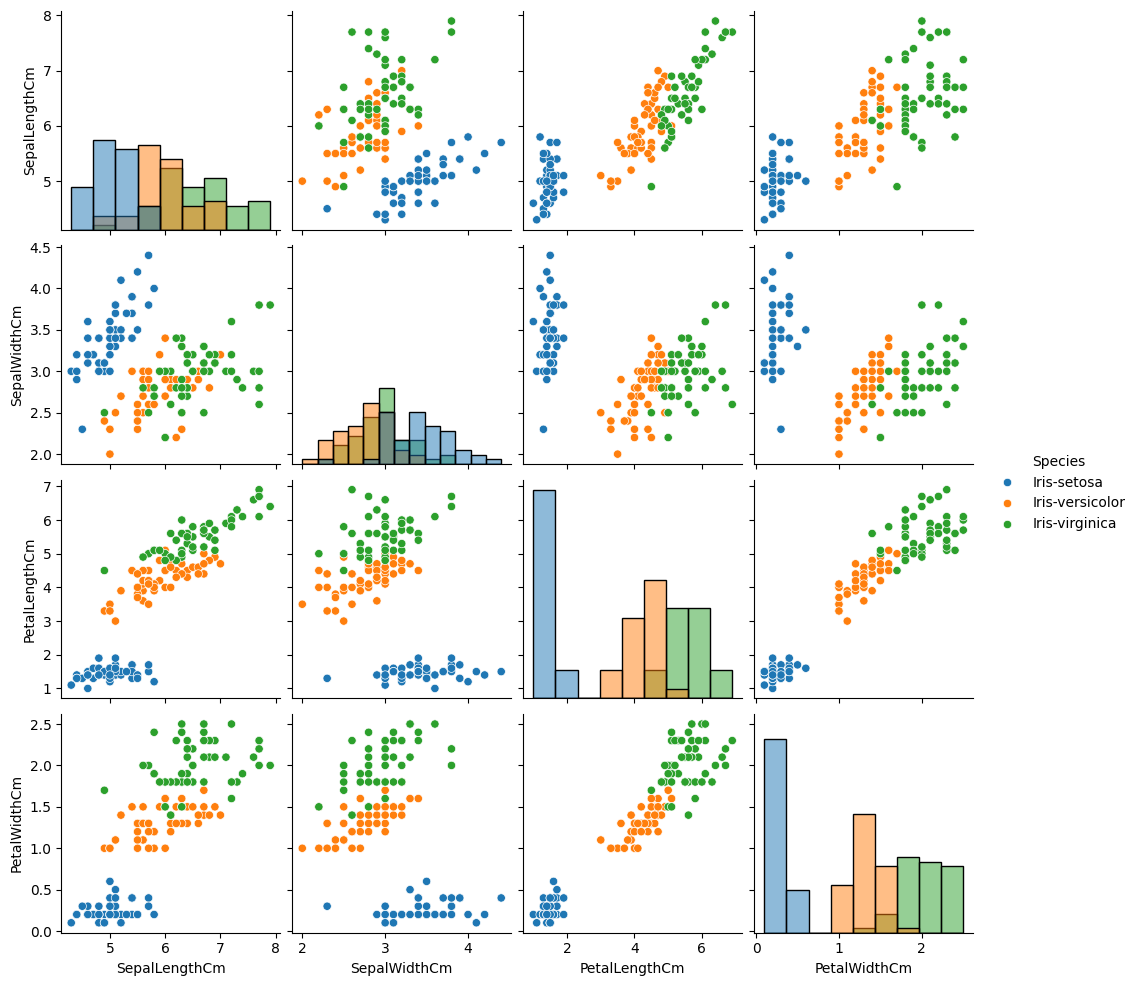

In [15]:
#pairplot
sns.pairplot(
    df,
    hue="Species",
    diag_kind="hist"
)

plt.show()

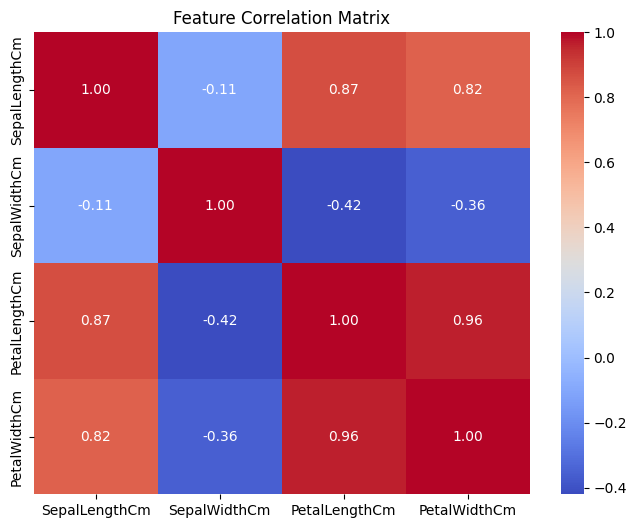

In [16]:
# Correlation analysis
plt.figure(figsize=(8,6))

sns.heatmap(
    x.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")
plt.show()

In [17]:
# Train/Test split
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [18]:
# Feature scaling
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [19]:
# Model Training
# Logistic Regression

model = LogisticRegression(
    max_iter=200
)

model.fit(
    x_train_scaled,
    y_train
)

LogisticRegression(max_iter=200)

In [20]:
# Prediction
y_pred = model.predict(x_test_scaled)

In [21]:
# Accuracy Evaluation
accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy: ", accuracy)

Accuracy:  0.9333333333333333


In [22]:
# Classification Report
print(
    classification_report(
        y_test,
        y_pred
    )
)

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.90      0.90      0.90        10
 Iris-virginica       0.90      0.90      0.90        10

       accuracy                           0.93        30
      macro avg       0.93      0.93      0.93        30
   weighted avg       0.93      0.93      0.93        30



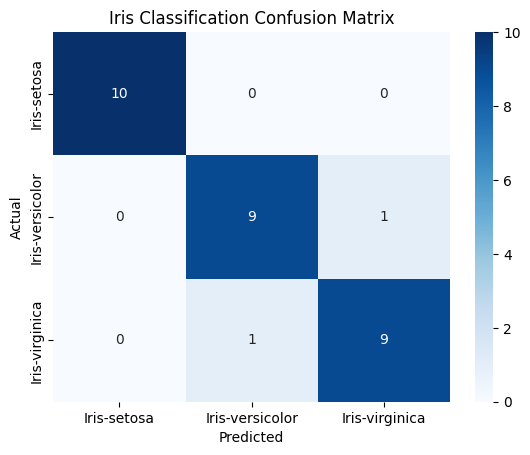

In [23]:
# Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Iris Classification Confusion Matrix")
plt.show()

In [24]:
# K-Nearest Neighbors(KNN)
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(
    x_train_scaled,
    y_train
)

KNeighborsClassifier()

In [25]:
# Prediction
y_pred = knn.predict(x_test_scaled)

In [26]:
# KNN model evaluation
accuracy = accuracy_score(
    y_test,
    y_pred
)

print("KNN Accuracy: ", accuracy)

KNN Accuracy:  0.9333333333333333


In [27]:
# Classification Report
print(
    classification_report(
        y_test,
        y_pred
    )
)

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30



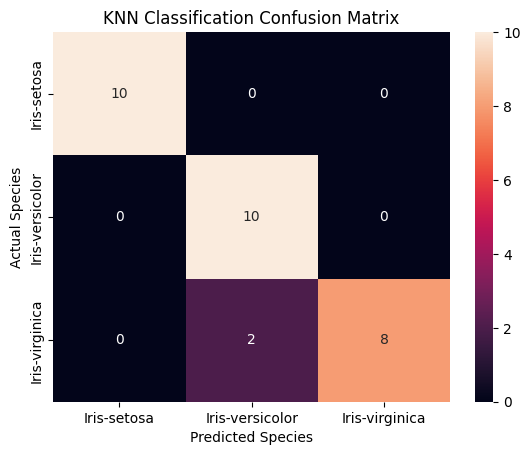

In [28]:
# Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=knn.classes_,
    yticklabels=knn.classes_
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("KNN Classification Confusion Matrix")
plt.show()

In [29]:
from sklearn.model_selection import cross_val_score

In [30]:
k_values = range(1, 21)

cv_scores =[]

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)

    scores = cross_val_score(
        knn,
        x_train_scaled,
        y_train,
        cv=5,
        scoring="accuracy"
    )

    cv_scores.append(scores.mean())

In [31]:
best_k = k_values[np.argmax(cv_scores)]

best_score = max(cv_scores)

print("Best K:", best_k)
print("Best Cross-Validation Accuracy:", best_score)

Best K: 5
Best Cross-Validation Accuracy: 0.9666666666666668


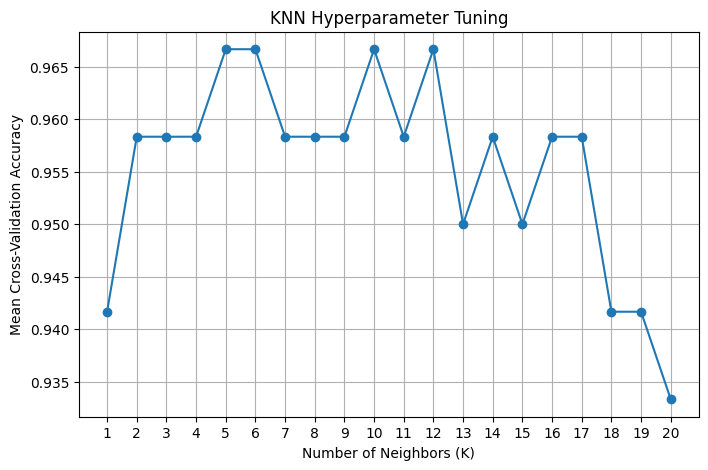

In [32]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    cv_scores,
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean Cross-Validation Accuracy")
plt.title("KNN Hyperparameter Tuning")

plt.xticks(list(k_values))
plt.grid(True)

plt.show()

In [33]:
final_knn = KNeighborsClassifier(
    n_neighbors=best_k
)

final_knn.fit(
    x_train_scaled,
    y_train
)

KNeighborsClassifier()

In [34]:
test_accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Test Accuracy:", test_accuracy)

Test Accuracy: 0.9333333333333333


**Decision Tree Algorithm**

In [35]:
x = df.drop(columns="Species")
y = df["Species"]

In [36]:
dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(
    x_train_scaled,
    y_train
)

DecisionTreeClassifier(random_state=42)

In [37]:
y_pred = dt_model.predict(x_test_scaled)

In [38]:
dt_accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.9


In [39]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.82      0.90      0.86        10
 Iris-virginica       0.89      0.80      0.84        10

       accuracy                           0.90        30
      macro avg       0.90      0.90      0.90        30
   weighted avg       0.90      0.90      0.90        30



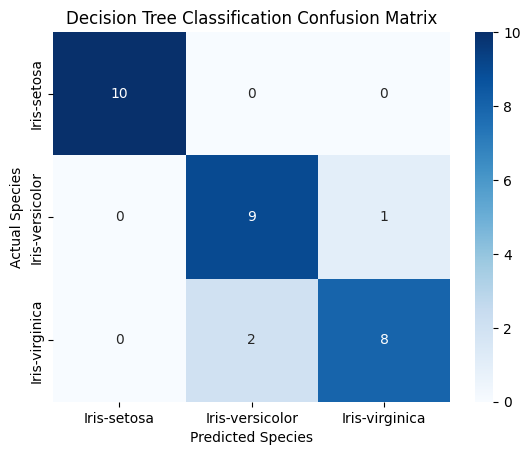

In [40]:
cm_dt = confusion_matrix(
    y_test,
    y_pred
)

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=dt_model.classes_,
    yticklabels=dt_model.classes_
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Decision Tree Classification Confusion Matrix")
plt.show()

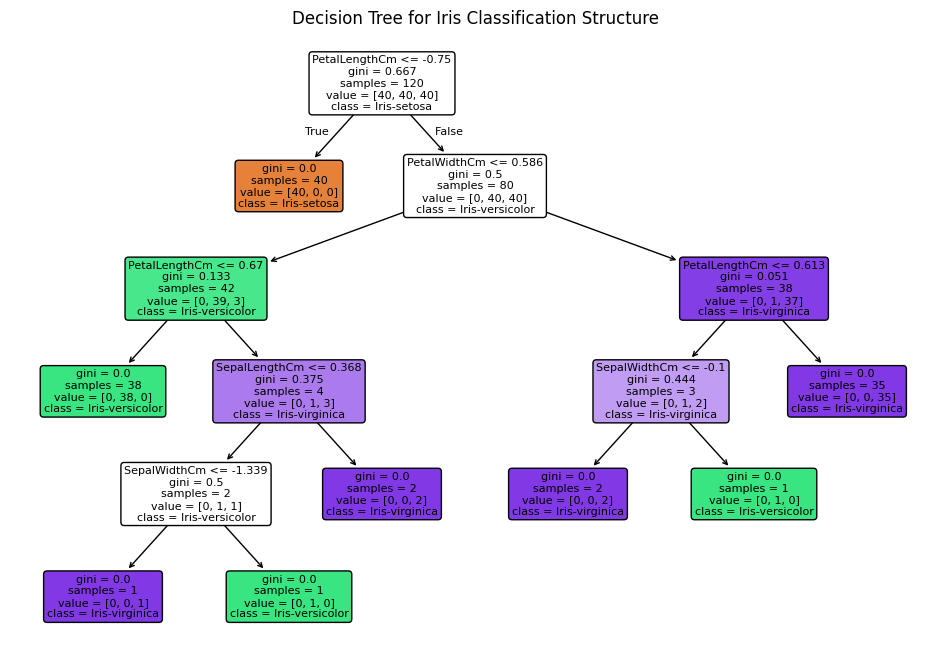

In [41]:
from sklearn.tree import plot_tree

plt.figure(figsize=(12, 8))

plot_tree(
    dt_model,
    filled=True,
    feature_names=x.columns,
    class_names=dt_model.classes_,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree for Iris Classification Structure")
plt.show()

In [42]:
importance = pd.Series(
    dt_model.feature_importances_,
    index=x.columns
).sort_values(ascending=False)

print(importance)



PetalLengthCm    0.558568
PetalWidthCm     0.406015
SepalWidthCm     0.029167
SepalLengthCm    0.006250
dtype: float64


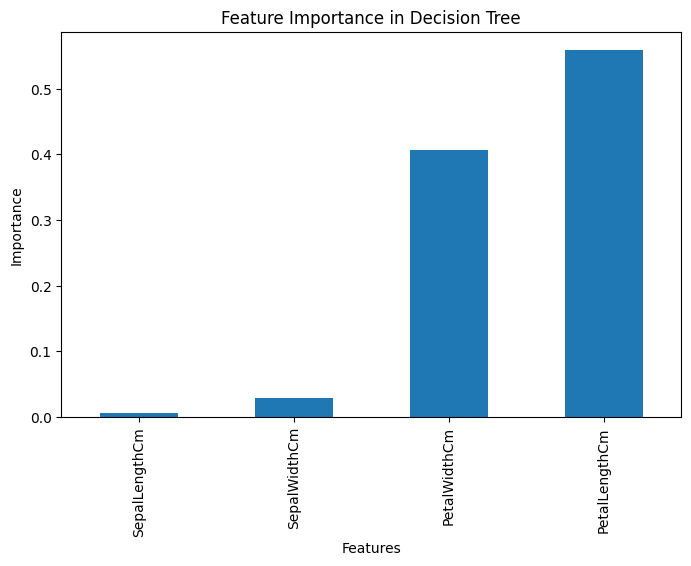

In [43]:
importance.sort_values().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance in Decision Tree")
plt.show()

In [45]:
x = df.drop(columns="Species")
y = df["Species"]

In [46]:
# Decision Tree Algorithm
dt_model = DecisionTreeClassifier(
    random_state=42
)

dt_model.fit(
    x_train_scaled,
    y_train
)

DecisionTreeClassifier(random_state=42)

In [47]:
y_pred = dt_model.predict(x_test_scaled)

In [48]:
dt_accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.9


In [49]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.82      0.90      0.86        10
 Iris-virginica       0.89      0.80      0.84        10

       accuracy                           0.90        30
      macro avg       0.90      0.90      0.90        30
   weighted avg       0.90      0.90      0.90        30



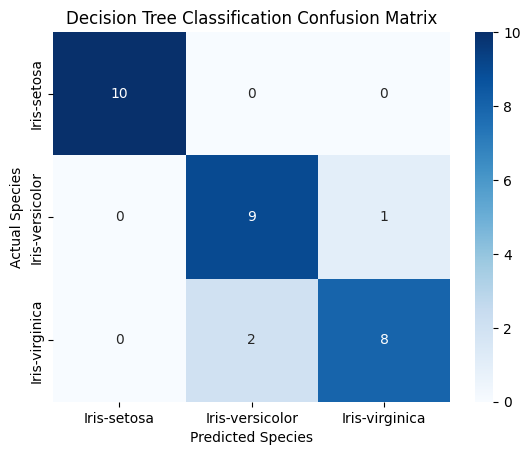

In [50]:
cm_dt = confusion_matrix(
    y_test,
    y_pred
)

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=dt_model.classes_,
    yticklabels=dt_model.classes_
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Decision Tree Classification Confusion Matrix")
plt.show()

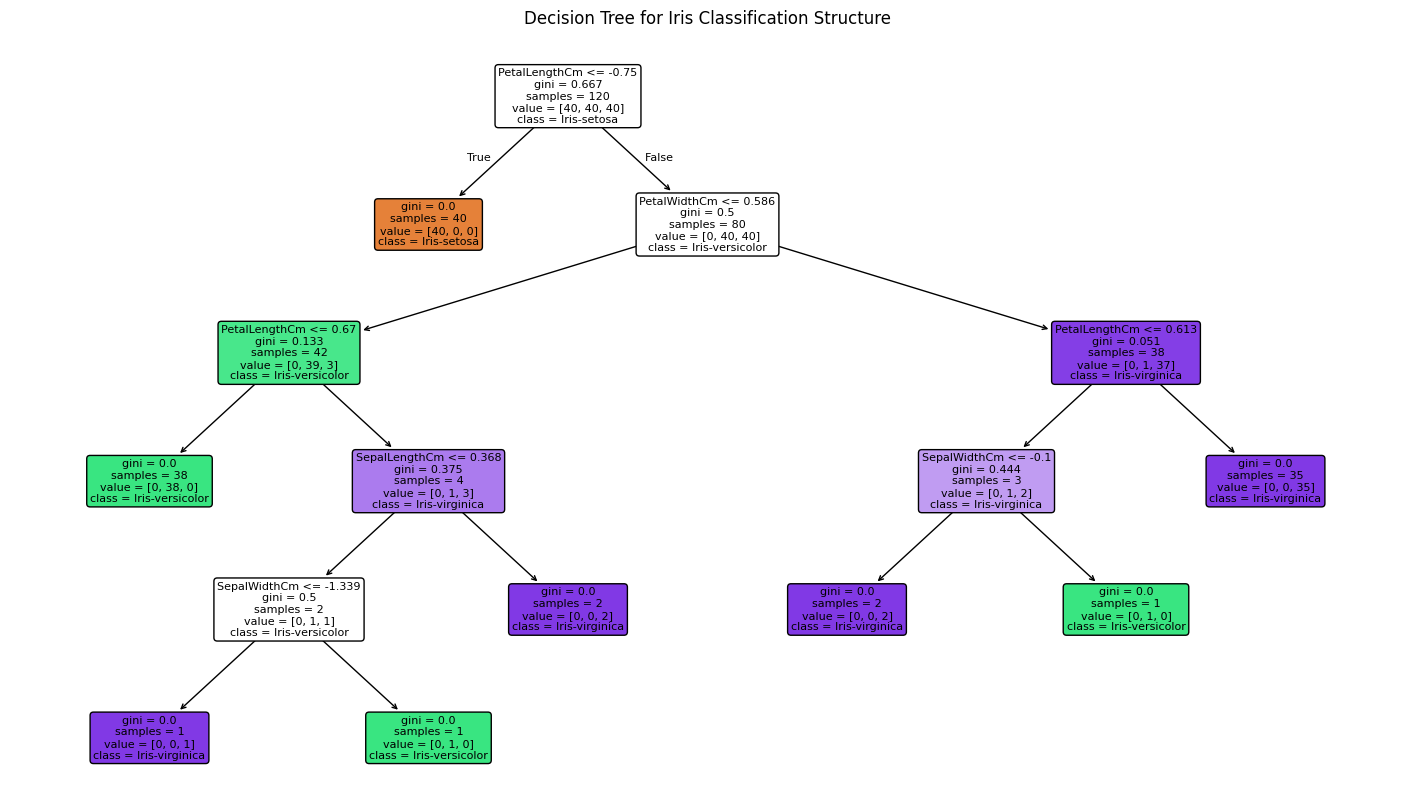

In [52]:
plt.figure(figsize=(18, 10))

plot_tree(
    dt_model,
    filled=True,
    feature_names=x.columns,
    class_names=dt_model.classes_,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree for Iris Classification Structure")
plt.show()

In [53]:
importance = pd.Series(
    dt_model.feature_importances_,
    index=x.columns
).sort_values(ascending=False)

print(importance)

PetalLengthCm    0.558568
PetalWidthCm     0.406015
SepalWidthCm     0.029167
SepalLengthCm    0.006250
dtype: float64


In [54]:
# Random Forest Algorithm
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(
    x_train_scaled,
    y_train
)

RandomForestClassifier(random_state=42)

In [55]:
y_pred = rf_model.predict(x_test_scaled)

In [56]:
rf_accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.9


In [57]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.82      0.90      0.86        10
 Iris-virginica       0.89      0.80      0.84        10

       accuracy                           0.90        30
      macro avg       0.90      0.90      0.90        30
   weighted avg       0.90      0.90      0.90        30



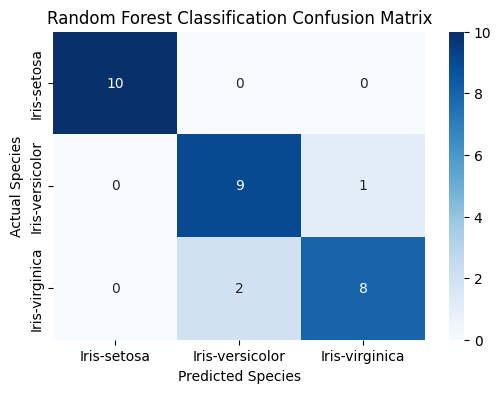

In [58]:
# Confusion Matrix
cm_rf = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6, 4))


sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("Random Forest Classification Confusion Matrix")
plt.show()

In [59]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=x.columns
).sort_values(ascending=False)

print(importance)

PetalWidthCm     0.437185
PetalLengthCm    0.431466
SepalLengthCm    0.116349
SepalWidthCm     0.015000
dtype: float64


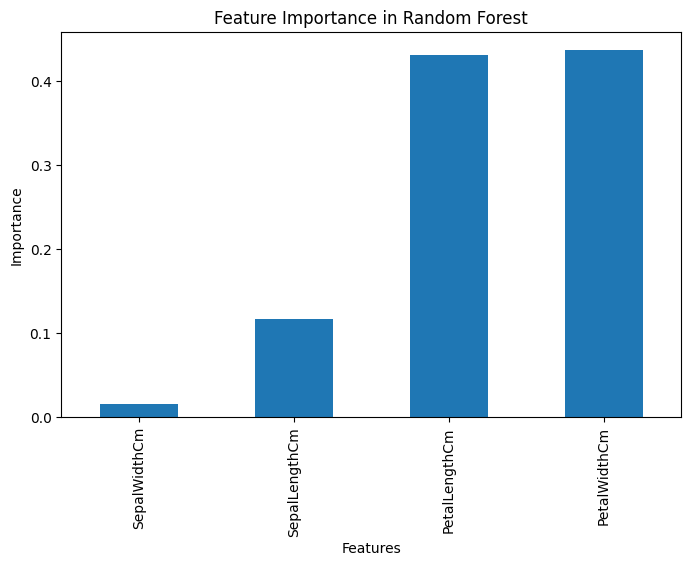

In [60]:
importance.sort_values().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.xlabel("Features")
plt.ylabel("Importance")
plt.title("Feature Importance in Random Forest")
plt.show()

In [61]:
# SVM Model
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    random_state=42
)

svm_model.fit(
    x_train_scaled,
    y_train
)

SVC(random_state=42)

In [62]:
y_pred = svm_model.predict(x_test_scaled)

In [63]:
svm_accuracy = accuracy_score(
    y_test,
    y_pred
)

print("SVM Accuracy:", svm_accuracy)

SVM Accuracy: 0.9666666666666667


In [64]:
# Classification Report
print(
    classification_report(
        y_test,
        y_pred
    )
)

                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



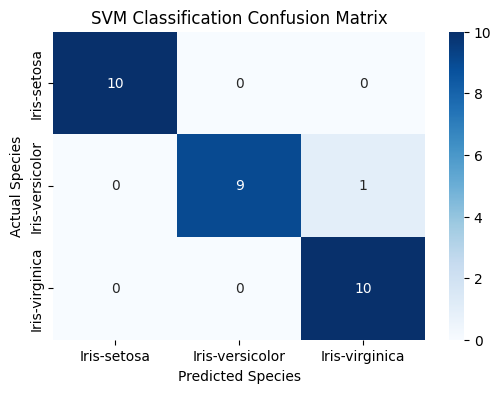

In [65]:
# Confusion Matrix
cm_svm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6, 4))
plt.title("SVM Classification Confusion Matrix")

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=svm_model.classes_,
    yticklabels=svm_model.classes_
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()